# Sanity checks of the November 2025 forecast

## Setup
We load the saved pipelines (the conservative one and the tuned one adopted in the app), the 2025 inference rows without one-hot encoding (the real price plan of the file) and the historical sales. Both pipelines were trained with all the 2021-2024 rows, so they have already seen 2024: the comparison with 2024 is a coherence check, not a validation.

In [1]:
# Import the libraries
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Make the src package importable from the notebooks folder and import the recursive forecast
sys.path.append(str(Path("..").resolve()))
from src.forecasting import recursive_forecast

# Load both pipelines and the data (paths relative to the notebooks folder)
modelos = {
    "Conservative": joblib.load("../models/pipeline_final.joblib"),
    "Tuned": joblib.load("../models/pipeline_final_tuned.joblib"),
}
inf = pd.read_csv("../data/processed/inferencia_df_sin_onehot.csv", parse_dates=["fecha"])
df_2024 = pd.read_csv("../data/processed/df_sin_onehot.csv", parse_dates=["fecha"]).query("año == 2024")
ventas = pd.read_csv("../data/raw/entrenamiento/ventas.csv", parse_dates=["fecha"])

# Cast the numeric and boolean columns of the pipeline input to float, as in training
cols_cat = ["nombre", "categoria", "subcategoria"]
cols_float = [c for c in modelos["Tuned"].feature_names_in_ if c not in cols_cat]
inf[cols_float] = inf[cols_float].astype(float)

def prever(datos, modelo):
    """Recursive forecast of the rows given (all products at once), sorted by date and product."""
    return recursive_forecast(modelo, datos).sort_values(["fecha", "producto_id"])

print(inf.shape, df_2024.shape, ventas.shape)

(720, 37) (720, 37) (3552, 10)


## A1. Total units of November 2025 vs history
The real price plan of the file is not modified. We forecast November 2025 for the 24 products with both pipelines (recursive, as in the app) and compare the total with the real total of November 2022, 2023 and 2024. The chart compares the daily total of the 24 products: forecast of each model against the real 2024 (Black Friday was on 2024-11-29 and is on 2025-11-28, so the peak is one day earlier in 2025).

In [2]:
# Total real units of November in each year (all the products)
nov = ventas[ventas["fecha"].dt.month == 11]
real_anual = nov.groupby(nov["fecha"].dt.year)["unidades_vendidas"].sum()

# Forecast of November 2025 with each model and its daily total
previsiones = {nombre: prever(inf, m) for nombre, m in modelos.items()}
totales = {f"Real Nov {anio}": real_anual[anio] for anio in [2022, 2023, 2024]}
totales.update({f"Forecast Nov 2025 ({nombre})": p["unidades_predichas"].sum() for nombre, p in previsiones.items()})

# Table: total and difference against the real 2024
tabla_a1 = pd.DataFrame({"Total units": totales})
tabla_a1["vs real 2024 (%)"] = (tabla_a1["Total units"] / real_anual[2024] - 1) * 100
tabla_a1.round(1)

,Total units,vs real 2024 (%)
Real Nov 2022,3805.0,-0.2
Real Nov 2023,4217.0,10.6
Real Nov 2024,3814.0,0.0
Forecast Nov 2025 (Conservative),4209.6,10.4
Forecast Nov 2025 (Tuned),3711.3,-2.7


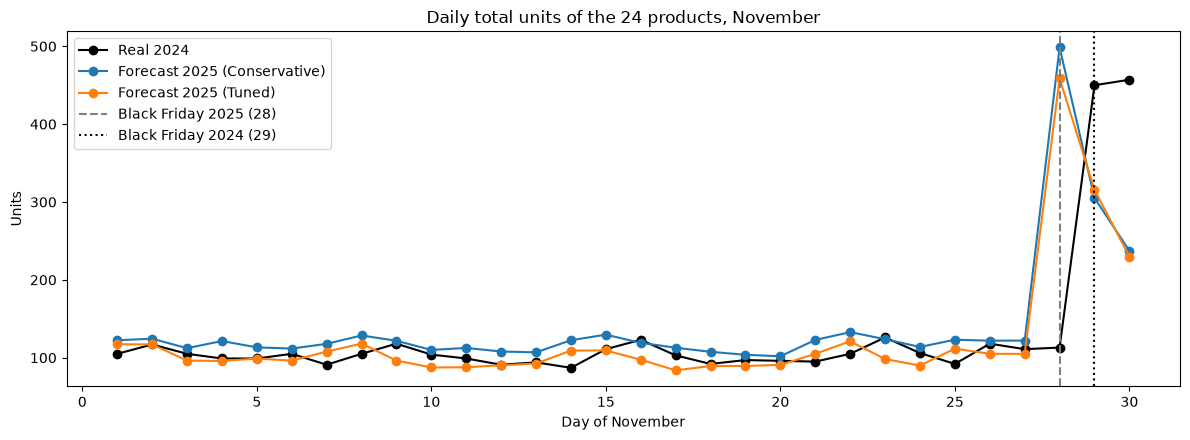

In [3]:
# Plot the daily total of the 24 products: forecasts of both models vs the real 2024
real_2024_dia = nov[nov["fecha"].dt.year == 2024].groupby(nov["fecha"].dt.day)["unidades_vendidas"].sum()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(real_2024_dia.index, real_2024_dia.values, color="black", marker="o", label="Real 2024")
for nombre, p in previsiones.items():
    dia = p.groupby(p["fecha"].dt.day)["unidades_predichas"].sum()
    ax.plot(dia.index, dia.values, marker="o", label=f"Forecast 2025 ({nombre})")
ax.axvline(28, color="gray", linestyle="--", label="Black Friday 2025 (28)")
ax.axvline(29, color="black", linestyle=":", label="Black Friday 2024 (29)")
ax.set_title("Daily total units of the 24 products, November")
ax.set_xlabel("Day of November")
ax.set_ylabel("Units")
ax.legend()
plt.tight_layout()
plt.show()

## A2. Counterfactual: the 2024 discount plan applied to the 2025 rows
We rebuild the 2025 rows so that, for each product and day, the discount (`descuento_porcentaje`, `precio_venta`, `ratio_precio`) is the one of 2024 for the same day of November. The 2025 base prices and competitors' prices are kept, and `precio_venta` is recomputed as `precio_base * (1 + discount / 100)`. If the gap with the history comes from the price plan, the forecast should move towards the real 2024 total. Since the discounts of 2024 peak on day 29 and those of 2025 on day 28, we also run an aligned variant where the 2025 days 24-28 take the discounts of the 2024 days 25-29 (the Black Friday week aligned on Black Friday), day 29 takes the 2024 day 30, and day 30 keeps its own 2025 plan.

In [4]:
# Check that the base prices are the same in 2024 and 2025, so the discounts are comparable
base_24 = df_2024.drop_duplicates("producto_id").set_index("producto_id")["precio_base"]
base_25 = inf.drop_duplicates("producto_id").set_index("producto_id")["precio_base"]
print("Same base prices in 2024 and 2025:", bool((base_24.sort_index() - base_25.sort_index()).abs().max() == 0))

# Discount of 2024 by product and day of November
desc_24 = df_2024.assign(dia=df_2024["fecha"].dt.day).set_index(["producto_id", "dia"])["descuento_porcentaje"]

def contrafactual(origen_dia):
    """2025 rows with the 2024 discounts; origen_dia maps each 2025 day to the 2024 day whose discount it takes (None = keep own plan)."""
    c = inf.copy()
    dia = c["fecha"].dt.day
    for i in c.index:
        fuente = origen_dia(dia[i])
        if fuente is not None:
            c.loc[i, "descuento_porcentaje"] = desc_24[(c.loc[i, "producto_id"], fuente)]
    c["precio_venta"] = c["precio_base"] * (1 + c["descuento_porcentaje"] / 100)
    c["ratio_precio"] = c["precio_venta"] / c["precio_competencia"]
    return c

# Variant 1: same day of November. Variant 2: aligned on Black Friday
variantes = {
    "2025 plan (file)": inf,
    "2024 discounts, same day": contrafactual(lambda d: d),
    "2024 discounts, aligned on BF": contrafactual(lambda d: d + 1 if 24 <= d <= 28 else (30 if d == 29 else (None if d == 30 else d))),
}

# Forecast with both models and compare with the real 2024 total
filas = {}
for nombre_v, datos in variantes.items():
    filas[nombre_v] = {nombre_m: prever(datos, m)["unidades_predichas"].sum() for nombre_m, m in modelos.items()}
tabla_a2 = pd.DataFrame(filas).T
for nombre_m in modelos:
    tabla_a2[f"{nombre_m}: change vs own 2025 plan (%)"] = (tabla_a2[nombre_m] / tabla_a2.loc["2025 plan (file)", nombre_m] - 1) * 100
    tabla_a2[f"{nombre_m}: vs real 2024 (%)"] = (tabla_a2[nombre_m] / real_anual[2024] - 1) * 100
print("Real 2024 total:", real_anual[2024])
tabla_a2.round(1)

Same base prices in 2024 and 2025: True


Real 2024 total: 3814


,Conservative,Tuned,Conservative: change vs own 2025 plan (%),Conservative: vs real 2024 (%),Tuned: change vs own 2025 plan (%),Tuned: vs real 2024 (%)
2025 plan (file),4209.6,3711.3,0.0,10.4,0.0,-2.7
"2024 discounts, same day",4153.2,3892.1,-1.3,8.9,4.9,2.0
"2024 discounts, aligned on BF",4379.8,4029.0,4.0,14.8,8.6,5.6


## A3. Conclusion: how much of the gap is explained by the discount plan
**Totals (24 products, November).** Real: 3,805 (2022), 4,217 (2023) and 3,814 (2024), mean 3,945. Forecast 2025 with the real plan of the file: tuned 3,711 (-2.7% vs 2024, -5.9% vs the 3-year mean), conservative 4,210 (+10.4% vs 2024, +6.7% vs the mean). At the level of all the products the tuned forecast is inside the year-to-year variation of the history (the real totals themselves move between 3,805 and 4,217); the large gap seen earlier (-20% vs 2024) was specific to three products (Pegasus 40, Domyos BM900 and Quechua MH500) and does not hold for the total.

**What the discount plan explains.**
- Tuned model: the gap with the real 2024 is -103 units. Replacing the 2025 discounts by those of 2024 on the same day adds +181 units (+4.9%), so the total goes to 3,892 (+2.0% vs 2024): the plan difference explains the whole gap (and overshoots it by about 78 units). With the 2024 discounts aligned on Black Friday the total is 4,029 (+5.6%), which overshoots more. The main difference in the plans is that the 2025 file has a -15% discount only on Black Friday (day 28), while 2024 kept a discount also on the following days.
- Conservative model: the gap with 2024 is +396 units and the plan explains none of it (same-day 2024 discounts change the total by -56 units, aligned ones by +170). Its excess over the history (+9% to +15% in every variant) comes from somewhere else than prices. We have not identified the cause: the same conservative model trained only with 2021-2023 did not overpredict the 2024 total (one-step +0.7%, recursive -8.7%), so it is not a simple general bias; possible candidates are the starting lags (October 2025 sales) or the extra year of training, but this was not tested.

**What remains unexplained.** For the tuned model, almost nothing at the total level (between -1.2% and +5.6% depending on how the 2024 plan is aligned). For the conservative model, about +9% over 2024 under any plan. The two models react very differently to the same change of plan (tuned +4.9% / +8.6%, conservative -1.3% / +4.0%), so the plan effect is model-dependent and the numbers above show how the models respond to prices, not a causal price effect. This is a coherence check on models already trained with 2024, not a validation.